# Optimizer walkthrough

Index tracking of a Bloomberg Agg style benchmark, built up step by step. Inputs: asset types, annualized active return goal `g`, horizon `T`, risk aversion, `k_max`, and `H` (planning horizons per solve).

Each month-end from `START_DATE` the notebook estimates the model inputs (`src.params`), solves for the portfolio (`src.optimize`), then measures the realised return over the next month. See `src/params/README.md` and `src/optimize/README.md` for definitions. POC: MBS inputs are rough.

In [1]:
import os, sys, time
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "workbook" else os.getcwd())
sys.path.insert(0, os.getcwd())
import warnings; warnings.filterwarnings("ignore")
from dataclasses import replace
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from data_cleaning import config as C
from src.params import build_inputs, build_cashflows, load_data
from src.optimize.model import Settings, solve_rebalance
from src.optimize.backtest import exit_cost, realised_returns
pd.options.display.float_format = "{:,.4f}".format

## 1. Inputs

`g` is quoted per year, the model works per month, so the notebook converts it. `T` sets how many monthly rebalances run (`N = 12 T`). Risk aversion maps to the variance multiplier `gamma` (weight on tracking variance against trading cost) and a scale on the duration, key-rate, spread and convexity tolerances. Higher risk aversion means larger `gamma` and tighter tolerances. These mappings are placeholders.

In [2]:
ASSET_TYPES = ["corporate", "treasury"]   # any subset
G_ANNUAL    = 0.0050        # annualized active return goal over the benchmark
START_DATE  = "2018-03-29"  # a month-end
T_YEARS     = 2             # horizon, N = 12 * T rebalances
RISK        = "medium"      # low | medium | high
K_MAX       = 150           # max number of bonds held
H           = 2             # planning horizons per solve (1 = single period at each month)
W           = 1_000_000     # wealth in dollars, sets the minimum lot weights
METHOD      = "misocp"      # "heuristic" (relax then truncate) or "misocp" (binary z)
BACKEND     = "gurobipy"    # "gurobipy" (src.optimize.grb, both methods) or "cvxpy" (CLARABEL heuristic, GUROBI via cvxpy)

# every other Settings field, defaults as in src/optimize/model.py
OPTS = dict(
    omega=None,             # weights on tracking variance per planning date, None = 1/H each
    max_active_w=0.02,      # x_i <= b_i + max_active_w
    psi_floor=False,        # lift psi to its sector median
    delta_D=0.25,           # |D'a| in years, scaled by tol_scale below
    delta_K=0.20,           # |K_j'a| per key rate, scaled
    delta_S=0.25,           # |D_spr'a|, scaled
    delta_C=15.0,           # |C'a|, scaled
    eps2=0.1,               # robustness multiplier in the return goal
    solver="CLARABEL",      # cvxpy heuristic solver
    mip_solver="GUROBI",    # cvxpy misocp solver
    mip_gap=1e-2,           # relative MIP gap
    mip_focus=2,            # Gurobi MIPFocus
    time_limit=120.0,       # Gurobi seconds per solve
    mip_cand=150,           # misocp: binaries only on the mip_cand largest stage-1 weights, None = all
    mip_warm=True,          # misocp: heuristic as MIP start
)

RISK_LEVELS = {  # placeholders
    "low": dict(gamma=3e2, tol_scale=2.0),
    "medium": dict(gamma=3e3, tol_scale=1.0),
    "high": dict(gamma=3e4, tol_scale=0.5),
}


def make_settings(risk=RISK, k_max=K_MAX, H=H, g=G_ANNUAL, method=METHOD, backend=BACKEND, **kw) -> Settings:
    """kw overrides any entry of OPTS (or any other Settings field) for this run."""
    r, o = RISK_LEVELS[risk], {**OPTS, **kw}
    g_m = (1 + g) ** (1 / 12) - 1
    for k in ("delta_D", "delta_K", "delta_S", "delta_C"):
        o[k] *= r["tol_scale"]
    o["omega"] = tuple(o["omega"] or [1 / H] * H)
    return replace(
        Settings(),
        H=H,
        gamma=r["gamma"],
        k_max=k_max,
        method=method,
        backend=backend,
        # the model requires mu'x - eps2 * ||Theta^(1/2) (x - b)|| >= b'mu - ret_slack, so a negative slack is a positive active goal
        ret_slack=-g_m,
        **o,
    )


settings = make_settings()
print(
    f"{settings.backend} {settings.method}, monthly active goal {1e4 * -settings.ret_slack:.2f} bp, gamma {settings.gamma:g}, k_max {settings.k_max}, H {settings.H}"
)

gurobipy misocp, monthly active goal 4.16 bp, gamma 3000, k_max 150, H 2


## 2. Data and rebalance dates

`load_data()` returns the bond universe, daily prices, the fitted Treasury curve and the month-end price panel. Rebalance dates are the first `N` month-ends from `START_DATE`. The last one needs a following month-end to measure its realised return, and Sigma needs at least 6 months of curve history before the first date.

In [3]:
data = load_data()
ends = data.panel.index.get_level_values("month_end").unique().sort_values()
N = round(12 * T_YEARS)
i0 = ends.searchsorted(pd.Timestamp(START_DATE))
assert ends[i0] == pd.Timestamp(
    START_DATE
), f"START_DATE must be a month-end, e.g. {ends[i0].date()}"
assert i0 >= 7, "need about 6 months of curve changes before START_DATE"
assert i0 + N < len(
    ends
), f"horizon runs past the data, last month-end is {ends[-1].date()}"
REB = list(ends[i0 : i0 + N])
END = ends[i0 + N]
# If we rebalance at the end of month T, then we need to see performance to T+1 (END)
print(
    f"{N} rebalances, {REB[0].date()} .. {REB[-1].date()}, last return measured to {END.date()}"
)
print(
    f"universe {len(data.universe):,} bonds, curve {data.curve.date.min().date()} .. {data.curve.date.max().date()}"
)

24 rebalances, 2018-03-29 .. 2020-02-28, last return measured to 2020-03-31
universe 20,619 bonds, curve 2017-08-01 .. 2025-12-31


## 3. Benchmark weights

This is index tracking, so the benchmark `b` has to match the chosen asset types. `agg_holdings_monthly` has one row per bond per month with `agg_market_value`. For month `t` we keep the selected asset types and set

`b_i = agg_market_value_i / sum over selected bonds of agg_market_value`

so the weights always sum to 1 within the selected sleeve. `build_inputs` reads `agg_weight` from the universe and then renormalizes again over the bonds that have a price at the as-of date, so we hand it a universe with `agg_weight` overwritten by the weights above (the processed universe has no such column).

In [4]:
holdings = pd.read_parquet(
    C.PROCESSED_DIR / "agg_holdings_monthly.parquet",
    columns=["holdings_date", "cusip", "asset_type", "agg_market_value"],
)
holdings["ym"] = holdings.holdings_date.dt.to_period("M")

# Filter to the selected asset types, gets used in benchmark_at() and data_for()
holdings = holdings[holdings.asset_type.isin(ASSET_TYPES)]


def benchmark_at(asof) -> pd.Series:
    """Market value weights of the selected asset types in the Agg holdings of asof's month, summing to 1."""
    h = holdings[holdings.ym == pd.Timestamp(asof).to_period("M")]
    mv = h.groupby("cusip").agg_market_value.sum()
    return mv / mv.sum()


def data_for(asof):
    """Data with the universe cut to the benchmark at asof and agg_weight set to the renormalized weights."""
    b = benchmark_at(asof)
    u = data.universe[data.universe.cusip.isin(b.index)].copy()
    u["agg_weight"] = u.cusip.map(b)
    return data._replace(universe=u)


# check at START_DATE: weights by asset type before and after renormalizing
h0 = pd.read_parquet(
    C.PROCESSED_DIR / "agg_holdings_monthly.parquet",
    columns=["holdings_date", "asset_type", "agg_market_value"],
)
h0 = h0[h0.holdings_date.dt.to_period("M") == pd.Timestamp(START_DATE).to_period("M")]
b0 = benchmark_at(START_DATE)
chk = pd.DataFrame(
    {
        "full Agg": h0.groupby("asset_type").agg_market_value.sum()
        / h0.agg_market_value.sum()
    }
)
sleeve = (
    pd.Series(
        b0.values,
        index=data.universe.set_index("cusip").asset_type.reindex(b0.index).values,
    )
    .groupby(level=0)
    .sum()
)
chk["selected sleeve"] = sleeve
chk.loc["total"] = chk.sum()
print(
    f"{len(b0):,} benchmark bonds at {START_DATE}, matched to the universe: {b0.index.isin(data.universe.cusip).mean():.1%} of bonds"
)
chk

5,486 benchmark bonds at 2018-03-29, matched to the universe: 100.0% of bonds


,full Agg,selected sleeve
asset_type,,
corporate,0.2779,0.4016
mbs,0.3080,NaN
treasury,0.4141,0.5984
total,1.0000,1.0000


## 4. Estimation at the first date

`build_inputs(asof, W, H, data=...)` estimates everything the optimizer needs as of `asof`, using data up to that date only. With `H = 1` there is one `PeriodInputs` (planning date t). Larger `H` ages every bond forward under today's curve, giving one more `PeriodInputs` per step.

What it computes, in order:
1. Fits NSS curve parameters for `asof`, then reprices each bond off the curve plus its own spread to get key-rate durations `K`, duration `D`, spread duration and convexity `C`.
2. Estimates the 8x8 key-rate covariance `Sigma` from monthly curve changes (Ledoit-Wolf), keeps 3 principal components, and forms the curve loadings `K Gamma Lambda^(1/2)`.
3. Adds one credit factor per corporate sector (the sector's implied common spread change each month, loading `-D_spr`). Treasuries have `D_spr = 0`, so they load on no credit factor and the spread-duration tolerance limits active credit exposure.
4. Estimates residual variance `psi` per bond from month-end returns net of the curve and credit factors, shrunk toward a sector prior `D^2 kappa` with a weight of 12 months.
5. Sets trading costs `c` (half the recent bid-ask), minimum lots `ell` from `W`, expected returns `mu_hat`, and benchmark weights `b` (renormalized over bonds priced at `asof`).

About a minute per date with all asset types (it refits on the full history up to `asof`).

In [5]:
asof = REB[0]
t = time.time()
P = build_inputs(asof, W, H=H, data=data_for(asof))
q = P.periods[0]
print(
    f"{asof.date()}: {len(P.cusips):,} bonds, built in {time.time() - t:.0f}s, sum(b) = {P.b.sum():.6f}"
)
pd.DataFrame(
    {
        "bonds": pd.Series(P.asset_type).value_counts(),
        "b weight": pd.Series(P.b, index=P.asset_type).groupby(level=0).sum(),
        "duration": pd.Series(q.D * P.b, index=P.asset_type).groupby(level=0).sum()
        / pd.Series(P.b, index=P.asset_type).groupby(level=0).sum(),
    }
)

2018-03-29: 5,313 bonds, built in 2s, sum(b) = 1.000000


,bonds,b weight,duration
corporate,5084,0.3942,7.4802
treasury,229,0.6058,6.0459


Estimated inputs: the three curve factors (share of key-rate variance each explains), residual variance by sector, and trading costs. `psi` for bonds with under 6 residual observations is the sector prior alone.

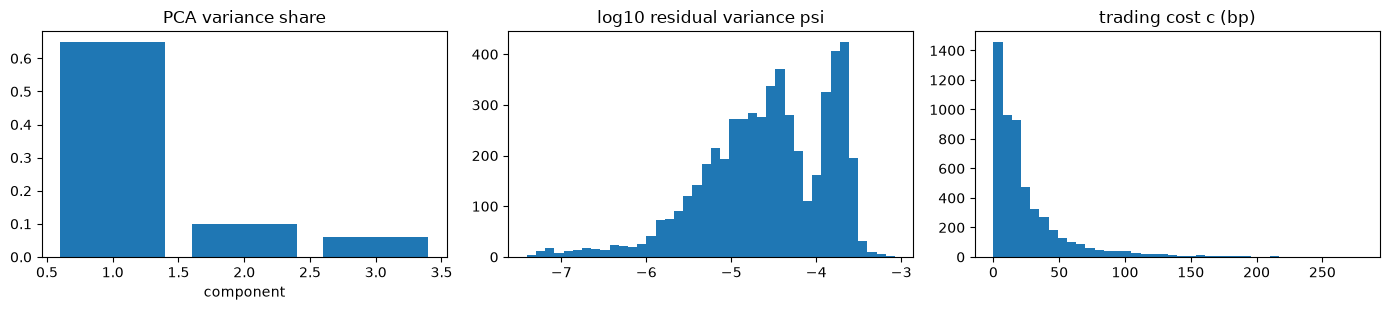

,psi median,cost median bp,stale share,bonds
industrial,0.0000,16.6617,0.0768,3009
financial,0.0000,13.8650,0.0603,1393
utility,0.0001,20.2253,0.2625,682
treasury,0.0000,2.4029,0.0000,229


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].bar(range(1, len(P.model.explained) + 1), P.model.explained)
ax[0].set_title("PCA variance share")
ax[0].set_xlabel("component")
ax[1].hist(np.log10(P.model.psi[P.model.psi > 0]), bins=40)
ax[1].set_title("log10 residual variance psi")
ax[2].hist(1e4 * P.c, bins=40)
ax[2].set_title("trading cost c (bp)")
plt.tight_layout()
plt.show()
pd.DataFrame(
    {
        "psi median": pd.Series(P.model.psi, index=P.sector).groupby(level=0).median(),
        "cost median bp": pd.Series(1e4 * P.c, index=P.sector)
        .groupby(level=0)
        .median(),
        "stale share": pd.Series(P.stale, index=P.sector).groupby(level=0).mean(),
        "bonds": pd.Series(P.sector).value_counts(),
    }
).sort_values("bonds", ascending=False)

## 5. Solve at the first date

`solve_rebalance(P, S, x_init, settings)` minimizes `gamma * (tracking variance) + trading cost` over weights `x` subject to: fully invested, no shorting, active weight caps, tolerances on active duration, spread duration, convexity and each key-rate duration, and the return goal (expected active return minus a robustness term `eps2 * ||Theta^(1/2) (x - b)||`).

Two ways to enforce the cardinality limit `k_max` and the minimum lots, picked by `METHOD`. `"heuristic"` (default, CLARABEL): stage 1 solves the relaxation, stage 2 keeps the `k_max` largest weights, forces them to at least the minimum lot, and re-solves. `"misocp"` (Gurobi): one solve with a binary `z_i` per bond, `x_i <= z_i`, `x_i >= ell_i z_i`, `sum z <= k_max`. Gurobi stops at `TIME_LIMIT` seconds and uses its best incumbent, so status `user_limit` means a feasible but not proven optimal portfolio. If the model is infeasible it drops the return goal first, then widens the tolerances (x2, x4, x8). `delta_scale` and `return_goal_dropped` report that.

Inputs the notebook prepares:
- `S`: candidate set, the 400 largest benchmark weights among eligible bonds (not stale, not exiting, minimum lot small enough that `k_max` lots fit) plus current holdings. Tracking is still measured against the full benchmark.
- `x_init`: current holdings. Zero at the first date (we start in cash, so the first trade pays full cost).
- `psi` is already shrunk toward a duration-scaled sector prior in `build_inputs`, so no extra floor is applied.

In [7]:
N_CAND = 1000


def candidates(P, hold: dict, k_max: int, H: int):
    """Candidate index set S and x_init (current holdings on S)."""
    q = P.periods[0]
    pos = {c: i for i, c in enumerate(P.cusips)}
    lot_ok = np.all([pe.ell <= 0.5 / k_max for pe in P.periods[:H]], axis=0)
    eligible = ~P.stale & ~q.exits & np.isfinite(q.mu_hat) & lot_ok
    # Select the top indices of N_CAND bonds by b_hat, ineligible bonds get -1 so they sort to the end
    top = np.argsort(-np.where(eligible, q.b_hat, -1))[:N_CAND]
    # Combine top candidates with currently held bonds
    S = np.unique(np.concatenate([top, [pos[c] for c in hold]])).astype(int)
    # Initialize x_init to the current holdings on S, defaulting to 0 if not held
    x_init = np.array([hold.get(P.cusips[i], 0.0) for i in S])
    return S, x_init



Pf = P
S, x_init = candidates(Pf, {}, settings.k_max, settings.H)
t = time.time()

# Solve the problem at the first rebalance date
sol = solve_rebalance(Pf, S, x_init, settings)
print(f"status {sol.status}, solved in {time.time() - t:.1f}s, |S| = {len(S)}")
print(
    f"held {int((sol.x[0] > 1e-6).sum())} bonds (k_max {settings.k_max}), return goal dropped: {sol.return_goal_dropped}, tolerance scale: {sol.delta_scale:g}"
)

status optimal, solved in 10.2s, |S| = 1000
held 150 bonds (k_max 150), return goal dropped: False, tolerance scale: 1


Result at the first date: every constraint of the model at the date-t portfolio, with its bounds (tolerances already multiplied by the tolerance scale), then the largest holdings. Active weights are `a = x - b` over all benchmark bonds (bonds outside `S` are at zero, so their active weight is `-b`). The return goal row is the margin over the goal, so it should be at least 0 unless the goal was dropped.

In [9]:
x0 = sol.x[0] / sol.x[0].sum()
a = -q.b_hat.copy()
a[S] += x0
s_, sc = settings, sol.delta_scale
held = x0 > 1e-9
cap = q.b_hat[S] + s_.max_active_w if s_.max_active_w is not None else np.full(len(S), np.inf)
th = np.sqrt(np.sum((Pf.theta_F.T @ a) ** 2) + np.sum(Pf.theta_psi * a**2))  # ||Theta^(1/2) (x - b)||
d_x = x0 - x_init

# (value, lower, upper) for every constraint in solve_rebalance, at h = 0
rows = {
    "budget: sum x": (x0.sum(), 1, 1),
    "no shorting: min x": (x0.min(), 0, np.inf),
    "active weight cap: max(x - b - cap)": ((x0 - cap).max(), -np.inf, 0),
    "exits: weight in exiting bonds": (x0[q.exits[S]].sum(), 0, 0),
    "cardinality: bonds held": (int(held.sum()), 0, s_.k_max),
    "min lot: min x / ell over held": ((x0[held] / q.ell[S][held]).min(), 1, np.inf),
    "trades: turnover, sum |x - x_init|": (np.abs(d_x).sum(), 0, np.inf),
    "active duration (yrs)": (q.D @ a, -s_.delta_D * sc, s_.delta_D * sc),
    "active spread duration": (q.D_spr @ a, -s_.delta_S * sc, s_.delta_S * sc),
    "active convexity": (q.C @ a, -s_.delta_C * sc, s_.delta_C * sc),
}
for tenor, v in zip(C.KEY_RATES, q.K.T @ a):
    rows[f"active KRD {tenor.lower()}"] = (v, -s_.delta_K * sc, s_.delta_K * sc)
# return goal: mu'x - eps2 * ||Theta^(1/2) (x - b)|| >= mu'b - ret_slack, shown as the active margin over the goal
rows["return goal: mu'a - eps2 ||Th^1/2 a|| + ret_slack (bp/mo)"] = (
    1e4 * (q.mu_hat @ a - s_.eps2 * th + s_.ret_slack), 0 if not sol.return_goal_dropped else -np.inf, np.inf)

tol = pd.DataFrame(rows, index=["value", "lower", "upper"]).T
tol["ok"] = (tol.value >= tol.lower - 1e-6) & (tol.value <= tol.upper + 1e-6)
# binding: value within solver tolerance of either bound (equalities always bind)
tol["binding"] = np.isclose(tol.value, tol.lower, rtol=1e-4, atol=1e-6) | np.isclose(tol.value, tol.upper, rtol=1e-4, atol=1e-6)
print(
    f"tolerance scale {sc:g}, return goal dropped {sol.return_goal_dropped}, "
    f"forecast tracking error {1e4 * np.sqrt(sol.track_var * 12):.1f} bp/yr, overlap with benchmark {1 - 0.5 * np.abs(a).sum():.1%}"
)
top = (
    pd.DataFrame(
        {"cusip": Pf.cusips[S], "sector": Pf.sector[S], "x": x0, "b": q.b_hat[S]}
    )
    .assign(active=lambda d: d.x - d.b)
    .merge(
        data.universe[
            [
                "cusip",
                "name",
            ]
        ],
        how="left",
        on="cusip",
    )
)
display(tol)
top[top.x > 1e-6].sort_values("x", ascending=False).head(10)

tolerance scale 1, return goal dropped False, forecast tracking error 11.0 bp/yr, overlap with benchmark 18.2%


,value,lower,upper,ok,binding
budget: sum x,1.0000,1.0000,1.0000,True,True
no shorting: min x,0.0000,0.0000,inf,True,True
active weight cap: max(x - b - cap),-0.0000,-inf,0.0000,True,True
exits: weight in exiting bonds,0.0000,0.0000,0.0000,True,True
cardinality: bonds held,150.0000,0.0000,150.0000,True,True
min lot: min x / ell over held,1.0000,1.0000,inf,True,True
"trades: turnover, sum |x - x_init|",1.0000,0.0000,inf,True,False
active duration (yrs),-0.0023,-0.2500,0.2500,True,False
active spread duration,0.0036,-0.2500,0.2500,True,False
active convexity,-0.3894,-15.0000,15.0000,True,False


,cusip,sector,x,b,active,name
175,11134LAB5,industrial,0.0203,0.0003,0.0200,BROADCOM CORPORATION/BROADCOM CAYM
353,37045XBD7,industrial,0.0203,0.0003,0.0200,GENERAL MOTORS FINANCIAL CO INC
40,00507UAP6,industrial,0.0203,0.0003,0.0200,ACTAVIS FUNDING SCS
390,38148FAB5,financial,0.0202,0.0002,0.0200,GOLDMAN SACHS GROUP INC/THE
540,61747YDW2,financial,0.0202,0.0002,0.0200,MORGAN STANLEY
64,026874CZ8,financial,0.0202,0.0002,0.0200,AMERICAN INTERNATIONAL GROUP INC
659,865622BM5,financial,0.0202,0.0002,0.0200,SUMITOMO MITSUI BANKING CORPORATIO
210,15135UAD1,industrial,0.0201,0.0001,0.0200,CENOVUS ENERGY INC
630,785592AE6,industrial,0.0187,0.0003,0.0184,SABINE PASS LIQUEFACTION LLC
385,38141GWQ3,financial,0.0183,0.0001,0.0182,GOLDMAN SACHS GROUP INC/THE


## 6. Roll forward over the horizon

The loop repeats steps 4 and 5 at every rebalance date. At each date:
1. Re-estimate (`build_inputs`) using only data up to that date, with the benchmark for that month.
2. Sell held bonds that left the benchmark (or have no price) at half the bid-ask, keeping the proceeds as cash. Solve starting from the remaining holdings, drifted by realised returns, so reinvesting the cash pays the buy cost.
3. Execute the date-t trades, paying `c' |trades|`.
4. Measure the realised return to the next month-end with `realised_returns` (month-end prices plus coupons paid; a bond with a stale price at either end takes its model return `mu_hat`).

Active return is the net portfolio return minus the benchmark return `b_hat' r`. Params are cached in memory by date, so re-running with another risk level or `k_max` skips the slow estimation (the cache is keyed by `H` and asset types, so change either and clear `PARAMS`).

In [10]:
PARAMS = {}
table = build_cashflows(
    data.universe[
        data.universe.asset_type.isin(ASSET_TYPES)
        & data.universe.maturity_date.notna()
        & data.universe.coupon_rate.notna()
    ].reset_index(drop=True),
    REB[0] - pd.Timedelta(days=400),
)


def rolling(s: Settings) -> pd.DataFrame:
    hold, c_prev, rows = {}, {}, []
    for k, d in enumerate(REB):
        if (d, s.H) not in PARAMS:
            PARAMS[(d, s.H)] = build_inputs(d, W, H=s.H, data=data_for(d))
        P = PARAMS[(d, s.H)]
        q, d1 = P.periods[0], ends[ends.get_loc(d) + 1]
        pos = {c: i for i, c in enumerate(P.cusips)}
        drop = {c: w for c, w in hold.items() if c not in pos}
        exit_c = exit_cost(drop, d, data.prices, c_prev)
        hold = {c: w / (1 - exit_c) for c, w in hold.items() if c in pos}
        S, x_init = candidates(P, hold, s.k_max, s.H)
        sol = solve_rebalance(P, S, x_init, s)
        x0 = sol.x[0] / sol.x[0].sum()
        d_x = x0 - x_init
        cost = float(P.c[S] @ np.abs(d_x))
        r, share_fb, bad, p0 = realised_returns(P, d, d1, data, table)
        gross = float(x0 @ r[S])
        net = (1 - exit_c) * (1 - cost) * (1 + gross) - 1
        cost = 1 - (1 - exit_c) * (1 - cost)
        bench = float(q.b_hat @ r)
        hold = {
            P.cusips[i]: w * (1 + r[i]) / (1 + gross) for i, w in zip(S, x0) if w > 1e-9
        }
        c_prev = {P.cusips[i]: P.c[i] for i, w in zip(S, x0) if w > 1e-9}
        a = -q.b_hat.copy()
        a[S] += x0
        rows.append(
            dict(
                date=d,
                ret_port=net,
                ret_bench=bench,
                active=net - bench,
                cost=cost,
                exit_cost=exit_c,
                turnover=float(d_x.clip(0).sum()),
                n_hold=int((x0 > 1e-6).sum()),
                n_bonds=len(P.cusips),
                te_fcst_ann=np.sqrt(sol.track_var * 12),
                act_D=float(q.D @ a),
                goal_dropped=sol.return_goal_dropped,
                delta_scale=sol.delta_scale,
                status=sol.status,
            )
        )
        print(
            f"{d.date()} active {1e4 * (net - bench):+6.1f} bp  cost {1e4 * cost:5.1f} bp  hold {rows[-1]['n_hold']:3d}  scale {sol.delta_scale:g}"
        )
    return pd.DataFrame(rows).set_index("date")


res = rolling(settings)

2018-03-29 active   +9.1 bp  cost   3.4 bp  hold 150  scale 1
2018-04-30 active  +10.3 bp  cost   1.1 bp  hold 150  scale 1
2018-05-31 active  +10.8 bp  cost   0.3 bp  hold 150  scale 1
2018-06-29 active   +2.6 bp  cost   0.5 bp  hold 150  scale 1
2018-07-31 active  +12.4 bp  cost   0.2 bp  hold 150  scale 1
2018-08-31 active   +9.1 bp  cost   0.1 bp  hold 150  scale 1
2018-09-28 active   -4.2 bp  cost   0.4 bp  hold 150  scale 1
2018-10-31 active  -17.8 bp  cost   0.1 bp  hold 150  scale 1
2018-11-30 active  -15.1 bp  cost   0.2 bp  hold 147  scale 1
2018-12-31 active  +55.1 bp  cost   0.3 bp  hold 150  scale 1
2019-01-31 active  +10.2 bp  cost   0.3 bp  hold 150  scale 1
2019-02-28 active  +21.1 bp  cost   0.2 bp  hold 150  scale 1
2019-03-29 active   -6.6 bp  cost   0.1 bp  hold 150  scale 1
2019-04-30 active  +11.2 bp  cost   0.2 bp  hold 149  scale 1
2019-05-31 active   +0.8 bp  cost   0.2 bp  hold 150  scale 1
2019-06-28 active  +11.4 bp  cost   0.3 bp  hold 150  scale 1
2019-07-

## 7. Results

Annualized active return is compared with the goal `g`. Realised tracking error is the annualized standard deviation of monthly active returns (needs several months to mean much). Months where `goal_dropped` is true had an infeasible return goal, so the active return was not targeted that month.

,value
months,24.0000
cum portfolio,0.1568
cum benchmark,0.1524
"active return, annualized",0.0019
goal g,0.0050
"tracking error, annualized",0.0118
avg turnover,0.1024
avg cost bp,0.4386
avg holdings,148.1667
goal dropped months,0.0000


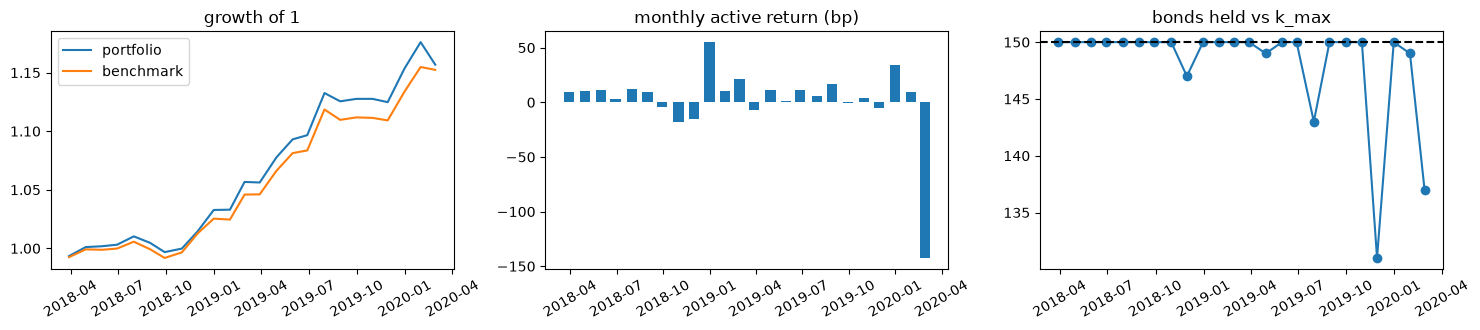

,ret_port,ret_bench,active,cost,turnover,n_hold,n_bonds,te_fcst_ann,act_D,goal_dropped,delta_scale,status
date,,,,,,,,,,,,
2018-03-29,-0.0066,-0.0075,0.0009,0.0003,1.0000,150,5313,0.0011,-0.0023,False,1.0000,optimal
2018-04-30,0.0077,0.0067,0.0010,0.0001,0.1158,150,5352,0.0013,-0.0019,False,1.0000,optimal
2018-05-31,0.0007,-0.0004,0.0011,0.0000,0.0490,150,5381,0.0012,-0.0099,False,1.0000,optimal
2018-06-29,0.0013,0.0011,0.0003,0.0000,0.0755,150,5411,0.0011,-0.0026,False,1.0000,optimal
2018-07-31,0.0071,0.0059,0.0012,0.0000,0.0751,150,5455,0.0011,-0.0002,False,1.0000,optimal
2018-08-31,-0.0055,-0.0064,0.0009,0.0000,0.0286,150,5477,0.0011,-0.0040,False,1.0000,optimal
2018-09-28,-0.0079,-0.0075,-0.0004,0.0000,0.0230,150,5505,0.0011,-0.0003,False,1.0000,optimal
2018-10-31,0.0030,0.0048,-0.0018,0.0000,0.0304,150,5502,0.0011,-0.0023,False,1.0000,optimal
2018-11-30,0.0146,0.0161,-0.0015,0.0000,0.0771,147,5519,0.0011,-0.0054,False,1.0000,optimal


In [11]:
def summary(res: pd.DataFrame, g=G_ANNUAL) -> pd.Series:
    n = len(res)
    cp_, cb = (1 + res.ret_port).prod(), (1 + res.ret_bench).prod()
    return pd.Series(
        {
            "months": n,
            "cum portfolio": cp_ - 1,
            "cum benchmark": cb - 1,
            "active return, annualized": (cp_ / cb) ** (12 / n) - 1,
            "goal g": g,
            "tracking error, annualized": (
                res.active.std(ddof=1) * np.sqrt(12) if n > 1 else np.nan
            ),
            "avg turnover": res.turnover.mean(),
            "avg cost bp": 1e4 * res.cost.mean(),
            "avg holdings": res.n_hold.mean(),
            "goal dropped months": int(res.goal_dropped.sum()),
        }
    )


display(summary(res).to_frame("value"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot((1 + res.ret_port).cumprod(), label="portfolio")
ax[0].plot((1 + res.ret_bench).cumprod(), label="benchmark")
ax[0].set_title("growth of 1")
ax[0].legend()
ax[1].bar(res.index, 1e4 * res.active, width=20)
ax[1].set_title("monthly active return (bp)")
ax[2].plot(res.n_hold, marker="o")
ax[2].axhline(settings.k_max, color="k", ls="--")
ax[2].set_title("bonds held vs k_max")
for a_ in ax:
    a_.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
res

,value
months,24.0000
cum portfolio,0.1542
cum benchmark,0.1524
"active return, annualized",0.0008
goal g,0.0050
"tracking error, annualized",0.0126
avg turnover,0.1057
avg cost bp,0.2477
avg holdings,137.5833
goal dropped months,0.0000


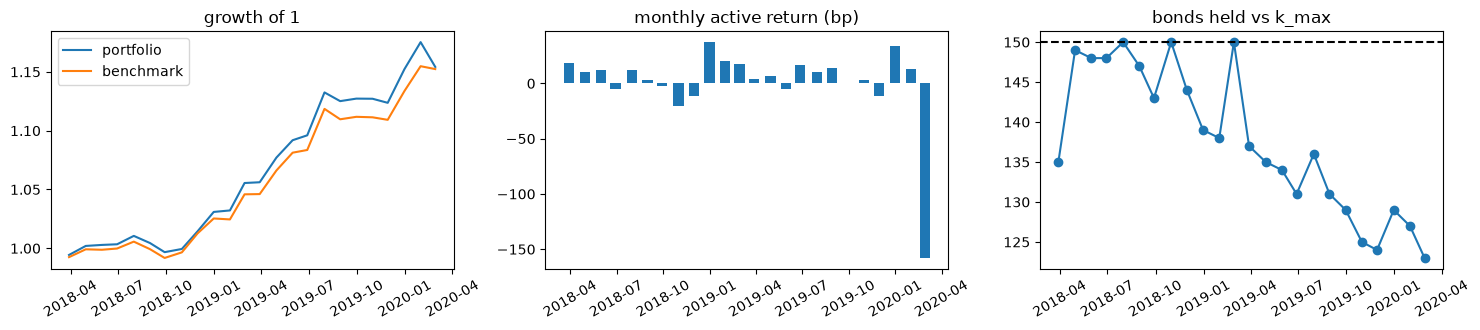

,ret_port,ret_bench,active,cost,turnover,n_hold,n_bonds,te_fcst_ann,act_D,goal_dropped,delta_scale,status
date,,,,,,,,,,,,
2018-03-29,-0.0056,-0.0075,0.0019,0.0002,1.0000,135,5313,0.0011,0.0010,False,1.0000,optimal
2018-04-30,0.0077,0.0067,0.0010,0.0001,0.1066,149,5352,0.0012,0.0020,False,1.0000,optimal
2018-05-31,0.0009,-0.0004,0.0012,0.0000,0.0471,148,5381,0.0012,-0.0100,False,1.0000,optimal
2018-06-29,0.0005,0.0011,-0.0005,0.0000,0.0380,148,5411,0.0011,-0.0070,False,1.0000,optimal
2018-07-31,0.0071,0.0059,0.0013,0.0000,0.0568,150,5455,0.0012,-0.0079,False,1.0000,optimal
2018-08-31,-0.0060,-0.0064,0.0003,0.0000,0.0531,147,5477,0.0012,-0.0037,False,1.0000,optimal
2018-09-28,-0.0077,-0.0075,-0.0002,0.0000,0.0225,143,5505,0.0012,-0.0032,False,1.0000,optimal
2018-10-31,0.0027,0.0048,-0.0021,0.0000,0.0384,150,5502,0.0011,-0.0015,False,1.0000,optimal
2018-11-30,0.0150,0.0161,-0.0012,0.0000,0.0783,144,5519,0.0012,-0.0045,False,1.0000,optimal


In [23]:
def summary(res: pd.DataFrame, g=G_ANNUAL) -> pd.Series:
    n = len(res)
    cp_, cb = (1 + res.ret_port).prod(), (1 + res.ret_bench).prod()
    return pd.Series(
        {
            "months": n,
            "cum portfolio": cp_ - 1,
            "cum benchmark": cb - 1,
            "active return, annualized": (cp_ / cb) ** (12 / n) - 1,
            "goal g": g,
            "tracking error, annualized": (
                res.active.std(ddof=1) * np.sqrt(12) if n > 1 else np.nan
            ),
            "avg turnover": res.turnover.mean(),
            "avg cost bp": 1e4 * res.cost.mean(),
            "avg holdings": res.n_hold.mean(),
            "goal dropped months": int(res.goal_dropped.sum()),
        }
    )


display(summary(res).to_frame("value"))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].plot((1 + res.ret_port).cumprod(), label="portfolio")
ax[0].plot((1 + res.ret_bench).cumprod(), label="benchmark")
ax[0].set_title("growth of 1")
ax[0].legend()
ax[1].bar(res.index, 1e4 * res.active, width=20)
ax[1].set_title("monthly active return (bp)")
ax[2].plot(res.n_hold, marker="o")
ax[2].axhline(settings.k_max, color="k", ls="--")
ax[2].set_title("bonds held vs k_max")
for a_ in ax:
    a_.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
res

## 8. Sensitivity to risk aversion and `k_max`

Re-runs the loop for each combination, reusing the cached estimates. Each run is a solve per month, so keep the grid small.

In [40]:
out = {}
for risk in RISK_LEVELS:
    for k in (50, K_MAX):
        out[(risk, k)] = summary(rolling(make_settings(risk=risk, k_max=k)))
pd.DataFrame(out).T.rename_axis(["risk", "k_max"])

2018-03-29 active  -22.2 bp  cost   1.4 bp  hold  50  scale 1
2018-04-30 active  +13.9 bp  cost   0.0 bp  hold  50  scale 1
2018-05-31 active  +23.8 bp  cost   0.0 bp  hold  50  scale 1
2018-06-29 active  -48.0 bp  cost   0.0 bp  hold  50  scale 1
2018-07-31 active  +19.1 bp  cost   0.0 bp  hold  50  scale 1
2018-08-31 active  -36.9 bp  cost   0.0 bp  hold  50  scale 1
2018-09-28 active  +27.2 bp  cost   0.0 bp  hold  50  scale 1
2018-10-31 active -104.5 bp  cost   7.1 bp  hold  50  scale 1
2018-11-30 active  -56.8 bp  cost   1.2 bp  hold  50  scale 1
2018-12-31 active +176.8 bp  cost   0.4 bp  hold  50  scale 1
2019-01-31 active  +54.3 bp  cost  12.4 bp  hold  50  scale 1
2019-02-28 active  +28.0 bp  cost   5.3 bp  hold  50  scale 1
2019-03-29 active   -6.9 bp  cost   5.2 bp  hold  50  scale 1
2019-04-30 active  -93.0 bp  cost   6.6 bp  hold  50  scale 1
2019-05-31 active +162.6 bp  cost   1.0 bp  hold  50  scale 1
2019-06-28 active   +8.3 bp  cost   5.4 bp  hold  50  scale 1
2019-07-

months  cum portfolio  cum benchmark  active return, annualized  \
risk   k_max                                                                    
low    50    24.0000         0.1743         0.1517                     0.0098   
       150   24.0000         0.1633         0.1517                     0.0050   
medium 50    24.0000         0.1815         0.1517                     0.0129   
       150   24.0000         0.1753         0.1517                     0.0102   
high   50    24.0000         0.2196         0.1517                     0.0291   
       150   24.0000         0.2133         0.1517                     0.0264   

              goal g  tracking error, annualized  avg turnover  avg cost bp  \
risk   k_max                                                                  
low    50     0.0050                      0.0249        0.4003       3.3812   
       150    0.0050                      0.0237        0.3579       2.8885   
medium 50     0.0050                      0.0358        0.5916       7.7778   
       150    0.0050                      0.0295        0.5529       6.7456   
high   50     0.0050                      0.0347        0.4224       5.6791   
       150    0.0050                      0.0340        0.3822       4.7156   

              avg holdings  goal dropped months  
risk   k_max                                     
low    50          50.0000              12.0000  
       150        150.0000              13.0000  
medium 50          50.0000              15.0000  
       150        150.0000              18.0000  
high   50          50.0000              19.0000  
       150        150.0000              22.0000